# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba,odsetek_%
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


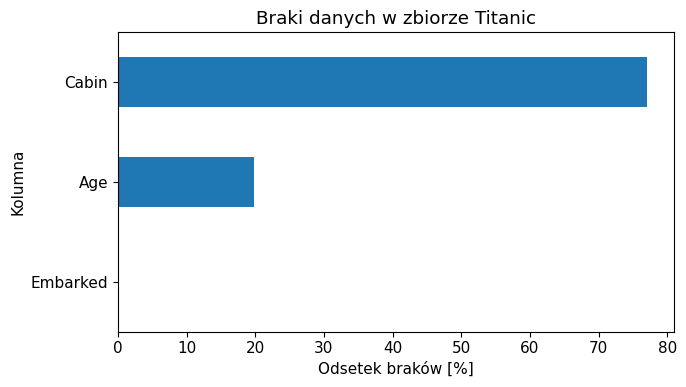

In [ ]:
braki = titanic.isna().sum()
odsetek = (titanic.isna().mean() * 100).round(2)

tab_braki = pd.DataFrame({"liczba": braki, "odsetek_%": odsetek})
tab_braki = tab_braki[tab_braki["liczba"] > 0].sort_values("liczba", ascending=False)
display(tab_braki)

ax = tab_braki["odsetek_%"].sort_values().plot.barh()
ax.set_xlabel("Odsetek braków [%]")
ax.set_ylabel("Kolumna")
ax.set_title("Braki danych w zbiorze Titanic")
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

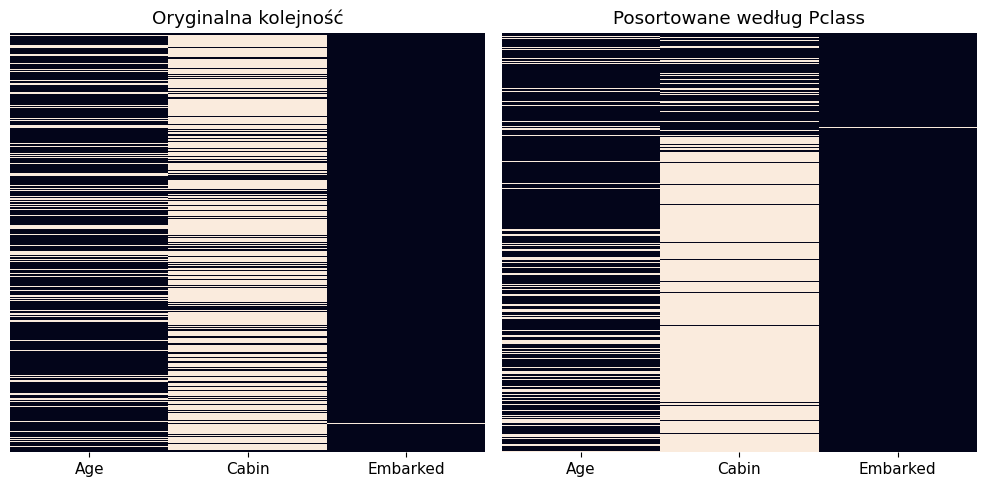

In [ ]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("Oryginalna kolejność")

posortowane = titanic.sort_values("Pclass", kind="stable")
sns.heatmap(posortowane[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("Posortowane według Pclass")

plt.tight_layout()
plt.show()

Na pierwszym wykresie braki wyglądają na rozrzucone chaotycznie. Po posortowaniu według klasy widać wyraźną strukturę. Braki Cabin są rzadkie w 1. klasie, a bardzo częste w 2. i zwłaszcza w 3. klasie. Braki Age także skupiają się głównie w 3. klasie. Braki zależą więc od klasy biletu, czyli nie są całkowicie losowe. Braki Embarked to tylko 2 pojedyncze wiersze.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Pclass
1    13.9
2     6.0
3    27.7
Name: Age, dtype: float64
Sex
female    16.9
male      21.5
Name: Age, dtype: float64
wiek znany    40.6
brak wieku    29.4
Name: Survived, dtype: float64
Ogółem: 38.4


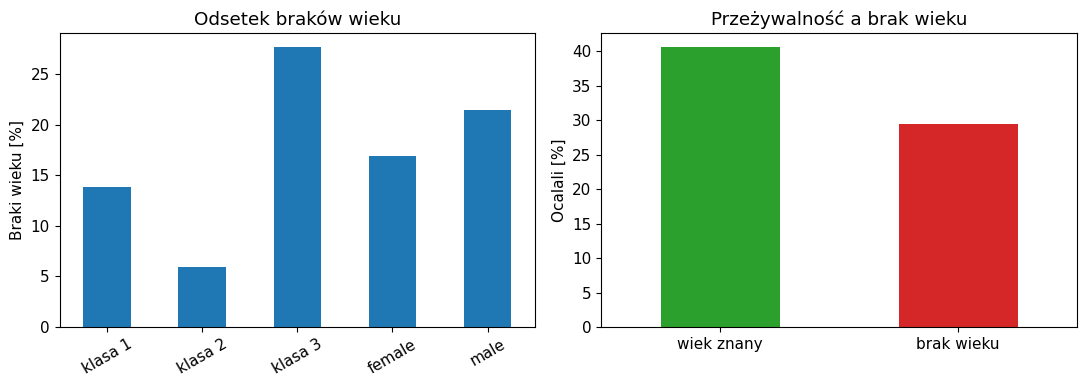

In [ ]:
brak_wieku = titanic["Age"].isna()


brak_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
brak_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100
print(brak_klasa.round(1))
print(brak_plec.round(1))


przezyli = titanic.groupby(brak_wieku)["Survived"].mean() * 100
przezyli.index = ["wiek znany", "brak wieku"]
print(przezyli.round(1))
print("Ogółem:", round(titanic["Survived"].mean() * 100, 1))


fig, axes = plt.subplots(1, 2, figsize=(11, 4))

brak_klasa.plot.bar(ax=axes[0], color="tab:blue", label="klasa")
brak_plec.rename(lambda s: s).plot.bar(ax=axes[0], alpha=0)
axes[0].clear()
pd.concat([brak_klasa.rename(lambda k: f"klasa {k}"), brak_plec]).plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_ylabel("Braki wieku [%]")
axes[0].set_title("Odsetek braków wieku")
axes[0].tick_params(axis="x", rotation=30)

przezyli.plot.bar(ax=axes[1], color=["tab:green", "tab:red"])
axes[1].set_ylabel("Ocalali [%]")
axes[1].set_title("Przeżywalność a brak wieku")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Nie, to nie jest MCAR. Braki wieku występują znacznie częściej w 3. klasie (27,7%) niż w 1. (13,9%) i 2. (6,0%), a także częściej u mężczyzn (21,5%) niż u kobiet (16,9%). Prawdopodobieństwo braku zależy więc od innych zmiennych, co wskazuje raczej na MAR. Wśród osób bez wieku przeżyło 29,4%, a wśród osób ze znanym wiekiem 40,6% (ogółem 38,4%). Usunięcie wierszy bez wieku zawyżyłoby odsetek ocalałych z 38,4% do 40,6% i zniekształciłoby skład klas, bo ubyłoby głównie pasażerów 3. klasy

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [ ]:
warianty = {
    "bez zmian": titanic,
    "dropna(Embarked)": titanic.dropna(subset=["Embarked"]),
    "dropna(Age)": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna(),
}

tabela = pd.DataFrame({
    nazwa: {
        "liczba wierszy": len(df),
        "% ocalałych": round(df["Survived"].mean() * 100, 1),
        "% 1. klasy": round((df["Pclass"] == 1).mean() * 100, 1),
    }
    for nazwa, df in warianty.items()
}).T
tabela

,liczba wierszy,% ocalałych,% 1. klasy
bez zmian,891.0,38.4,24.2
dropna(Embarked),889.0,38.2,24.1
dropna(Age),714.0,40.6,26.1
dropna(),183.0,67.2,86.3


Najbardziej zniekształca dane dropna(): przez braki w Cabin zostaje tylko 183 z 891 wierszy, odsetek ocalałych rośnie z 38,4% do 67,2%, a 1. klasy z 24,2% do 86,3%, więc zbiór przestaje być reprezentatywny. dropna(Age) usuwa 177 wierszy i lekko przesuwa dane (40,6% ocalałych, 26,1% 1. klasy), bo braki wieku nie są losowe. dropna(Embarked) usuwa 2 wiersze i prawie nic nie zmienia.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

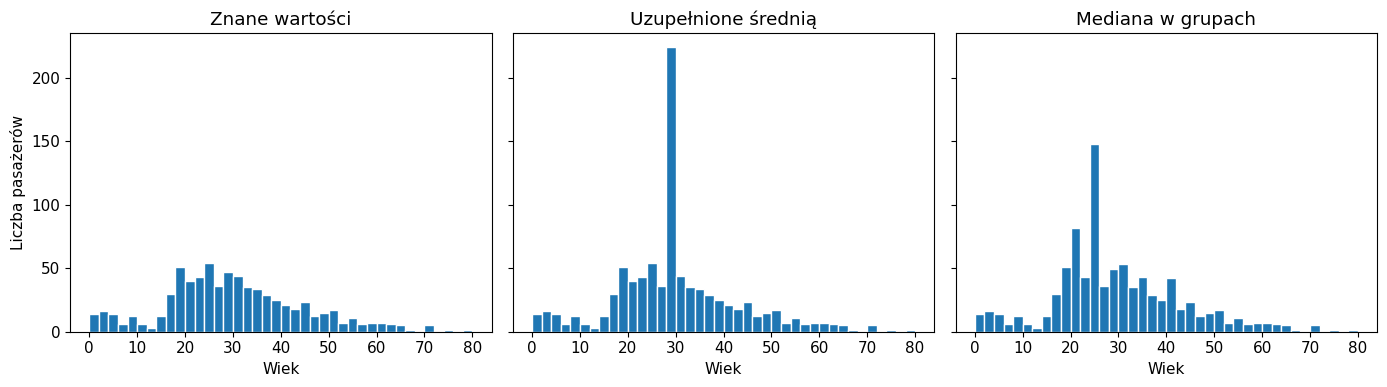

Age             14.53
wiek_srednia    13.00
wiek_grupy      13.30
dtype: float64


In [ ]:

titanic["Age_brak"] = titanic["Age"].isna()


titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
mediana_grup = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediana_grup)


biny = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (kol, tytul) in zip(axes, [("Age", "Znane wartości"),
                                   ("wiek_srednia", "Uzupełnione średnią"),
                                   ("wiek_grupy", "Mediana w grupach")]):
    ax.hist(titanic[kol].dropna(), bins=biny, edgecolor="white")
    ax.set_title(tytul)
    ax.set_xlabel("Wiek")
axes[0].set_ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()


print(titanic[["Age", "wiek_srednia", "wiek_grupy"]].std().round(2))

Odchylenie standardowe wynosi 14,53 dla znanych wartości, 13,00 dla uzupełnienia średnią i 13,30 dla mediany w grupach. Obie metody zaniżają zmienność, ale uzupełnienie średnią bardziej zniekształca rozkład: na histogramie powstaje sztuczny, wysoki słupek w okolicy średniej (ok. 30 lat). Mediana w grupach (klasa × płeć) rozkłada uzupełnione wartości na kilka punktów, więc zachowuje kształt rozkładu lepiej.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

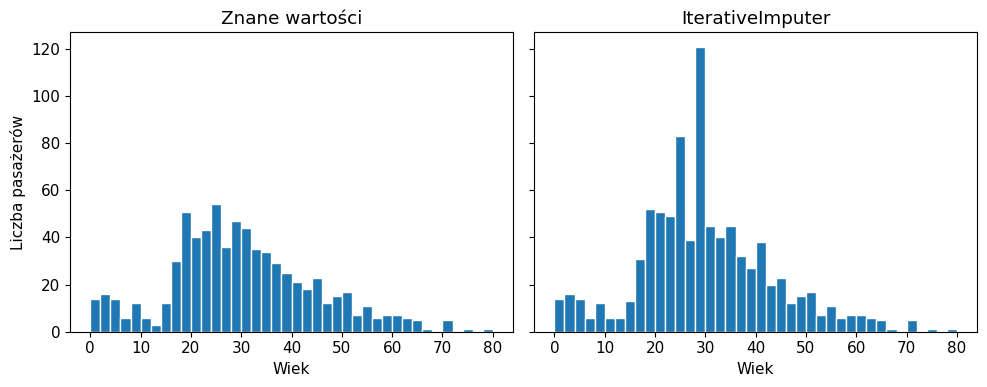

Age             14.53
wiek_srednia    13.00
wiek_grupy      13.30
wiek_model      13.64
dtype: float64


In [ ]:
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

dane = titanic[["Age", "Pclass", "SibSp", "Parch", "Fare"]].copy()
dane["Sex_01"] = (titanic["Sex"] == "female").astype(int)

imputer = IterativeImputer(random_state=0, max_iter=10)
wynik = imputer.fit_transform(dane)
titanic["wiek_model"] = wynik[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].hist(titanic["Age"].dropna(), bins=biny, edgecolor="white")
axes[0].set_title("Znane wartości")
axes[1].hist(titanic["wiek_model"], bins=biny, edgecolor="white")
axes[1].set_title("IterativeImputer")
for ax in axes:
    ax.set_xlabel("Wiek")
axes[0].set_ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()

print(titanic[["Age", "wiek_srednia", "wiek_grupy", "wiek_model"]].std().round(2))

Odchylenie standardowe wynosi 14,53 dla znanych wartości, 13,00 dla średniej, 13,30 dla mediany w grupach i 13,64 dla IterativeImputer. Imputacja modelem zachowuje zmienność najlepiej, bo wartości zależą od klasy, liczby krewnych, ceny biletu i płci, a nie są jedną stałą. Mimo to odchylenie jest nadal mniejsze niż w danych oryginalnych, bo model przewiduje wartości „typowe“ dla danych cech i nie odtwarza pełnego rozrzutu. Histogram jest łagodniejszy niż przy średniej, bez jednego sztucznego słupka.

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [ ]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print(mieszkania.dtypes)
print(mieszkania.isna().sum())
print(mieszkania["powierzchnia"].unique())

id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
['65' '48' '72' '55' '80' nan '60' '45' '70' '90' '58' '52' '68' '0' '75'
 '62' '50' 'brak' '66' '85' '54' '95' '56' '42' '78' '88' '64' '51' '69'
 '46' '82' '76']


Pandas widzi tylko 8 braków: 4 w powierzchnia i 4 w rok_budowy. To wartości N/A i NA, które pandas domyślnie traktuje jako brak. Kolumna powierzchnia (podobnie rok_budowy i pietro) ma typ tekstowy (object), bo oprócz liczb zawiera napisy, np. "brak", których pandas nie rozpoznaje jako braków. Jedna wartość tekstowa zmienia typ całej kolumny.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [ ]:
for kol in ["powierzchnia", "rok_budowy", "pietro", "parking", "balkon", "stan"]:
    print(f"--- {kol} ---")
    print(mieszkania[kol].value_counts(dropna=False).to_string())
    print()

mieszkania[["liczba_pokoi", "liczba_pieter", "cena_m2", "cena_total"]].describe()

--- powierzchnia ---
powierzchnia
NaN     4
0       3
55      2
48      2
60      2
62      2
70      2
72      2
58      2
brak    2
65      1
45      1
52      1
90      1
68      1
80      1
75      1
50      1
66      1
85      1
54      1
95      1
56      1
42      1
78      1
88      1
64      1
51      1
69      1
46      1
82      1
76      1

--- rok_budowy ---
rok_budowy
NaN     4
brak    3
2010    2
2018    2
2020    2
2015    2
2017    2
2019    2
2016    2
2014    2
2011    2
2013    2
2001    1
1998    1
2012    1
1995    1
2005    1
2008    1
1999    1
2003    1
2009    1
2021    1
1997    1
2007    1
2002    1
1996    1
2006    1
2022    1
2000    1
2004    1

--- pietro ---
pietro
2       9
1       8
3       7
4       6
6       3
0       3
5       3
-999    2
7       2
brak    1
8       1

--- parking ---
parking
Tak    34
Nie     6
?       5

--- balkon ---
balkon
Tak    35
Nie     7
?       3

--- stan ---
stan
Dobry           28
Bardzo dobry    11
Do remontu       

,liczba_pokoi,liczba_pieter,cena_m2,cena_total
count,45.000000,45.000000,45.000000,4.500000e+01
mean,2.688889,6.911111,9746.666667,6.590822e+05
std,0.924962,3.043788,2735.914348,1.502189e+05
min,1.000000,2.000000,-999.000000,4.250000e+05
25%,2.000000,4.000000,8900.000000,5.750000e+05
50%,3.000000,7.000000,9700.000000,6.480000e+05
75%,3.000000,9.000000,11000.000000,7.056000e+05
max,5.000000,15.000000,15000.000000,1.232000e+06


Wartości oznaczające brak: powierzchnia: "brak", "N/A", 0; rok_budowy: "brak", "NA"; pietro: "brak", -999; parking i balkon: "?"; cena_m2: -1 i -999 (widać to w describe() jako wartość minimalną).

Pułapka z zerem: 0 w powierzchnia to brak danych, bo mieszkanie nie może mieć 0 m2 0 w pietro to prawidłowa wartość, czyli parter (zgodnie z opisem kolumny). Dlatego "0" trafia do słownika tylko dla powierzchnia.





In [ ]:
braki_slownik = {
    "powierzchnia": ["brak", "N/A", "0"],
    "rok_budowy": ["brak", "NA"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
print(mieszkania.dtypes)
print(mieszkania.isna().sum())

id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [ ]:
print(mieszkania["stan"].value_counts())

mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})
print(mieszkania["stan"].value_counts())

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


W kolumnie stan występuje wartość 很好, czyli chińskie „bardzo dobrze“. Pozostałe to Dobry, Bardzo dobry i Do remontu. Najpewniej to błąd wpisania albo kodowania. Zamieniłem ją na Bardzo dobry, bo to najbliższe znaczeniowo odpowiednie. Nie usuwałem wiersza, bo reszta jego danych jest poprawna, a kolumna nie ma innych braków.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

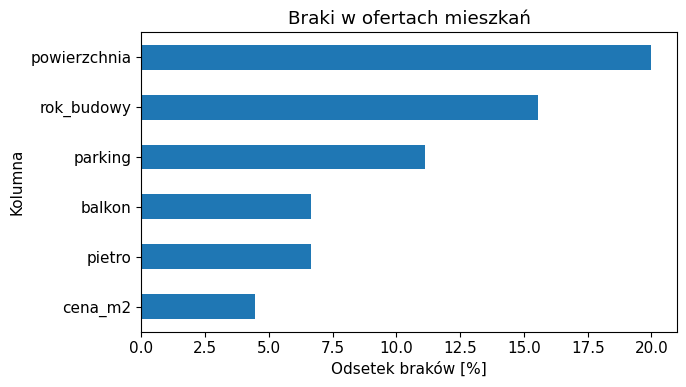

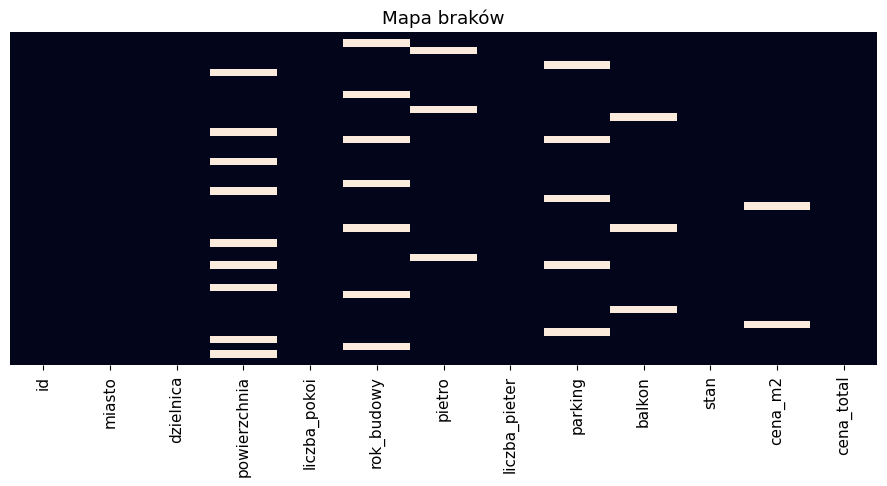

,powierzchnia,rok_budowy,pietro,parking,balkon,cena_m2
powierzchnia,1.00,-0.21,-0.13,-0.00,-0.13,-0.11
rok_budowy,-0.21,1.00,-0.11,0.04,0.13,-0.09
pietro,-0.13,-0.11,1.00,-0.09,-0.07,-0.06
parking,-0.00,0.04,-0.09,1.00,-0.09,-0.08
balkon,-0.13,0.13,-0.07,-0.09,1.00,-0.06
cena_m2,-0.11,-0.09,-0.06,-0.08,-0.06,1.00


In [ ]:

odsetek = (mieszkania.isna().mean() * 100)
odsetek = odsetek[odsetek > 0].sort_values()

ax = odsetek.plot.barh()
ax.set_xlabel("Odsetek braków [%]")
ax.set_ylabel("Kolumna")
ax.set_title("Braki w ofertach mieszkań")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.heatmap(mieszkania.isna(), cbar=False, yticklabels=False)
plt.title("Mapa braków")
plt.tight_layout()
plt.show()


kol_z_brakami = mieszkania.columns[mieszkania.isna().any()]
mieszkania[kol_z_brakami].isna().corr().round(2)

Najwięcej braków ma powierzchnia (20%), potem rok_budowy (ok. 16%) i parking (ok. 11%), a pietro, balkon i cena_m2 mają ich po kilka. Na mapie braków widać, że są rozrzucone po różnych wierszach i prawie się nie pokrywają. Potwierdza to macierz korelacji: wszystkie wartości są bliskie zera (od -0,21 do 0,13), więc nie ma kolumn, które mają braki w tych samych wierszach. Braki wyglądają na losowe i niezależne od siebie, a brak w jednej kolumnie nie wskazuje na brak w innej.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [ ]:

mieszkania["powierzchnia_brak"] = mieszkania["powierzchnia"].isna()
mieszkania["cena_m2_brak"] = mieszkania["cena_m2"].isna()


kompletne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
zgodne = np.isclose(kompletne["powierzchnia"] * kompletne["cena_m2"], kompletne["cena_total"])
print("Zgodnych wierszy:", zgodne.mean() * 100, "%")


print("Braki przed:", mieszkania["powierzchnia"].isna().sum(), mieszkania["cena_m2"].isna().sum())
mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(mieszkania["cena_total"] / mieszkania["powierzchnia"])
print("Braki po:", mieszkania["powierzchnia"].isna().sum(), mieszkania["cena_m2"].isna().sum())

Zgodnych wierszy: 100.0 %
Braki przed: 9 2
Braki po: 0 0


Zależność cena_total = powierzchnia × cena_m2 zachodzi w 100% kompletnych wierszy. Dzięki temu odtworzyłem wszystkie 9 braków w powierzchnia (jako cena_total / cena_m2) i 2 braki w cena_m2 (jako cena_total / powierzchnia), czyli 11 braków. Po tym kroku w obu kolumnach nie ma już braków, a wartości są dokładne, nie szacowane.

### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [ ]:

for kol in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[kol + "_brak"] = mieszkania[kol].isna()


print("całościowa:", mieszkania["rok_budowy"].median())
print(mieszkania.groupby("miasto")["rok_budowy"].median())
print(mieszkania.groupby("stan")["rok_budowy"].median())


for kol in ["parking", "balkon"]:
    znane = (mieszkania[kol] == "Tak").sum() / mieszkania[kol].notna().sum()
    dominanta = (mieszkania[kol].fillna("Tak") == "Tak").mean()
    nieznane = (mieszkania[kol] == "Tak").mean()
    print(f"{kol}: wśród znanych {znane:.1%}, dominanta {dominanta:.1%}, 'nieznane' {nieznane:.1%}")


mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(
    mieszkania.groupby("stan")["rok_budowy"].transform("median"))
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)
mieszkania["parking"] = mieszkania["parking"].fillna("nieznane")
mieszkania["balkon"] = mieszkania["balkon"].fillna("nieznane")


print("Braki łącznie:", mieszkania.isna().sum().sum())

całościowa: 2011.5
miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
parking: wśród znanych 85.0%, dominanta 86.7%, 'nieznane' 75.6%
balkon: wśród znanych 83.3%, dominanta 84.4%, 'nieznane' 77.8%
Braki łącznie: 0


rok_budowy: mediana całościowa to 2011,5. Mediany według miasta wahają się od 2001,5 (Gdańsk) do 2015 (Warszawa), a według stanu od 1997 (Do remontu) przez 2010 (Dobry) do 2019 (Bardzo dobry). Wybrałem grupy według stan, bo rozrzut median jest większy (22 lata wobec 13,5), a stan dobrze oddaje wiek budynku.

pietro: użyłem liczba_pieter // 2, bo uwzględnia wysokość budynku (mediana całościowa dałaby piętro 3 także w budynku 4-piętrowym).

parking i balkon: wybrałem kategorię "nieznane". Dominanta zawyżałaby odsetek mieszkań z udogodnieniem (parking: 85,0% wśród znanych, 86,7% po dominancie, 75,6% przy „nieznane“). Kategoria „nieznane“ niczego nie zakłada, a flaga braku i tak zachowuje informację.

### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

PRZED:


,powierzchnia,rok_budowy,cena_m2
count,36.00,38.00,43.00
mean,64.64,2010.29,10223.26
std,13.68,7.83,1611.69
min,42.00,1995.00,8200.00
25%,54.75,2004.25,9000.00
50%,63.00,2011.50,9800.00
75%,72.75,2016.75,11100.00
max,95.00,2022.00,15000.00


PO:


,powierzchnia,rok_budowy,cena_m2
count,45.00,45.00,45.00
mean,64.93,2010.64,10244.34
std,12.76,7.41,1623.86
min,42.00,1995.00,8200.00
25%,56.00,2006.00,9000.00
50%,62.00,2011.00,9800.00
75%,72.00,2017.00,11200.00
max,95.00,2022.00,15000.00


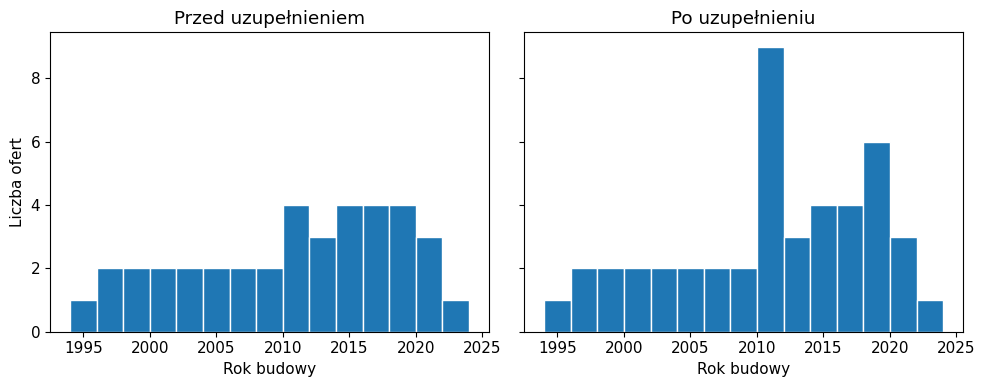

In [ ]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kol = ["powierzchnia", "rok_budowy", "cena_m2"]

print("PRZED:")
display(surowe[kol].describe().round(2))
print("PO:")
display(mieszkania[kol].describe().round(2))

biny_rok = np.arange(1994, 2026, 2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].hist(surowe["rok_budowy"].dropna(), bins=biny_rok, edgecolor="white")
axes[0].set_title("Przed uzupełnieniem")
axes[1].hist(mieszkania["rok_budowy"], bins=biny_rok, edgecolor="white")
axes[1].set_title("Po uzupełnieniu")
for ax in axes:
    ax.set_xlabel("Rok budowy")
axes[0].set_ylabel("Liczba ofert")
plt.tight_layout()
plt.show()

Zmiany są niewielkie. powierzchnia: średnia 64,64 -> 64,93, odchylenie 13,68 -> 12,76 (liczba obserwacji 36 -> 45). rok_budowy: średnia 2010,29 ->2010,64, odchylenie 7,83 -> 7,41, mediana 2011,5 ->2011. cena_m2: średnia 10223 ->10244, odchylenie 1612 ->1624. Odchylenia nieco spadły, bo uzupełnione wartości leżą blisko środka grup. Na histogramie rok_budowy pojawiają się wyższe słupki wokół 2010 i 2019 (wartości median grup Dobry i Bardzo dobry), ale kształt rozkładu jest zachowany. Nie ma więc istotnej zmiany rozkładów.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` |"brak", "N/A", 0 |9 | odtworzenie: cena_total / cena_m2|zależność zachodzi w 100% kompletnych wierszy, wartość jest dokładna |
| `cena_m2` |-1, -999 | 2| odtworzenie: cena_total / powierzchnia|j.w. |
| `rok_budowy` |"NA", "brak" |7 |mediana w grupach wg stan + flaga |stan dobrze różnicuje wiek budynku (mediany 1997–2019) |
| `pietro` |"brak", -999	|3 | liczba_pieter // 2 + flaga| uwzględnia wysokość budynku; 0 to parter, nie brak|
| `parking` |"?" |5 | kategoria "nieznane" + flaga| nie zawyża odsetka mieszkań z parkingiem|
| `balkon` |"?" |3 |kategoria "nieznane" + flaga |j.w.|
| `stan` |brak braków, ale błędna wartość "很好" (1 raz) | 0| zamiana na "Bardzo dobry"| chińskie „bardzo dobrze“, błąd wpisania; reszta wiersza poprawna|

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [ ]:
dane = surowe.copy()
dane["stan"] = dane["stan"].replace({"很好": "Bardzo dobry"})
dane["powierzchnia"] = dane["powierzchnia"].fillna(dane["cena_total"] / dane["cena_m2"])
dane["cena_m2"] = dane["cena_m2"].fillna(dane["cena_total"] / dane["powierzchnia"])

warianty_rok = {
    "bez uzupełniania (znane)": dane["rok_budowy"],
    "mediana całościowa": dane["rok_budowy"].fillna(dane["rok_budowy"].median()),
    "mediana wg miasta": dane["rok_budowy"].fillna(dane.groupby("miasto")["rok_budowy"].transform("median")),
    "mediana wg stanu": dane["rok_budowy"].fillna(dane.groupby("stan")["rok_budowy"].transform("median")),
}

for nazwa, s in warianty_rok.items():
    print(f"{nazwa:28s} r = {s.corr(dane['cena_m2']):.3f}")

bez uzupełniania (znane)     r = 0.709
mediana całościowa           r = 0.678
mediana wg miasta            r = 0.710
mediana wg stanu             r = 0.697


Korelacja rok_budowy z cena_m2: dla danych bez braków 0,709; mediana całościowa 0,678; mediana wg miasta 0,710; mediana wg stanu 0,697. Najmniej zmienia korelację uzupełnianie medianą według miasta, bo cena_m2 mocno zależy od miasta. Mediana całościowa zmienia ją najbardziej, bo wstawia tę samą wartość niezależnie od ceny. Wybór metody ma więc znaczenie, choć przy 7 brakach różnice są małe.

W zadaniu 12 wybrałem grupy według stan, bo lepiej odzwierciedlają wiek budynku, ale pod względem zachowania korelacji z ceną lepsze okazało się miasto (różnica względem danych bez braków: 0,001 wobec 0,012). Wybór grup to kompromis między sensem merytorycznym a wpływem na kolejne analizy.